# 02 — Preprocessing (C-MAPSS FD004)

Continues from `01_data_loading_eda.ipynb`. Goal: turn the raw, operating-condition-confounded sensor readings into a clean, health-focused feature set that UMAP, PCA, K-Means, and GMM can all use fairly.

**What this notebook does, in order:**
1. Map sensor codes (`s_1`...`s_21`) to their physical meaning
2. Detect the 6 operating regimes (fit on train only)
3. Decide which sensors to drop, using actual variance decomposition — not guesswork
4. Remove the operating-condition confound via per-condition normalization
5. Check remaining sensor correlations
6. Build RUL labels
7. Save the final processed train/test sets

Everything that touches test data reuses parameters *fitted on train only* — this is the same leakage discipline as the engine-wise split in notebook 1, just applied to normalization instead of splitting.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

pd.set_option('display.max_columns', 30)

index_names = ['unit_number', 'time_cycles']
setting_names = ['setting_1', 'setting_2', 'setting_3']
sensor_names = [f's_{i}' for i in range(1, 22)]
col_names = index_names + setting_names + sensor_names

DATA_DIR = '/mnt/user-data/uploads'
train = pd.read_csv(f'{DATA_DIR}/train_FD004.txt', sep=r'\s+', header=None, names=col_names)
test  = pd.read_csv(f'{DATA_DIR}/test_FD004.txt',  sep=r'\s+', header=None, names=col_names)

print(train.shape, test.shape)

(61249, 26) (41214, 26)


## 1. What each sensor physically measures

C-MAPSS's own documentation (Saxena et al., 2008, Table 2) lists exactly 21 sensor outputs in a fixed order, which maps directly onto `s_1`...`s_21` in this file:

In [2]:
sensor_meaning = {
 's_1':'T2 - Total temperature at fan inlet (°R)',
 's_2':'T24 - Total temperature at LPC outlet (°R)',
 's_3':'T30 - Total temperature at HPC outlet (°R)',
 's_4':'T50 - Total temperature at LPT outlet (°R)',
 's_5':'P2 - Pressure at fan inlet (psia)',
 's_6':'P15 - Total pressure in bypass-duct (psia)',
 's_7':'P30 - Total pressure at HPC outlet (psia)',
 's_8':'Nf - Physical fan speed (rpm)',
 's_9':'Nc - Physical core speed (rpm)',
 's_10':'epr - Engine pressure ratio (P50/P2)',
 's_11':'Ps30 - Static pressure at HPC outlet (psia)',
 's_12':'phi - Ratio of fuel flow to Ps30 (pps/psi)',
 's_13':'NRf - Corrected fan speed (rpm)',
 's_14':'NRc - Corrected core speed (rpm)',
 's_15':'BPR - Bypass ratio',
 's_16':'farB - Burner fuel-air ratio',
 's_17':'htBleed - Bleed enthalpy',
 's_18':'Nf_dmd - Demanded fan speed (rpm)',
 's_19':'PCNfR_dmd - Demanded corrected fan speed (rpm)',
 's_20':'W31 - HPT coolant bleed (lbm/s)',
 's_21':'W32 - LPT coolant bleed (lbm/s)',
}
pd.DataFrame.from_dict(sensor_meaning, orient='index', columns=['meaning'])

,meaning
s_1,T2 - Total temperature at fan inlet (°R)
s_2,T24 - Total temperature at LPC outlet (°R)
s_3,T30 - Total temperature at HPC outlet (°R)
s_4,T50 - Total temperature at LPT outlet (°R)
s_5,P2 - Pressure at fan inlet (psia)
s_6,P15 - Total pressure in bypass-duct (psia)
s_7,P30 - Total pressure at HPC outlet (psia)
s_8,Nf - Physical fan speed (rpm)
s_9,Nc - Physical core speed (rpm)
s_10,epr - Engine pressure ratio (P50/P2)


## 2. Detect the 6 operating regimes — fit on train only

We already found 6 distinct regimes from the 3 operational settings in notebook 1. Here we fit that K-Means model on **train settings only**, then use `.predict()` (not `.fit()`) on test settings. If we fit separately on test, we could get a different regime numbering/boundary than train — silently breaking the per-condition normalization we're about to build.

In [3]:
op_kmeans = KMeans(n_clusters=6, n_init=10, random_state=42)
train['op_cond'] = op_kmeans.fit_predict(train[setting_names])
test['op_cond']  = op_kmeans.predict(test[setting_names])

print('Train op_cond counts:'); print(train['op_cond'].value_counts().sort_index())
print('\nTest op_cond counts:'); print(test['op_cond'].value_counts().sort_index())

Train op_cond counts:
op_cond
0    15395
1     9224
2     9139
3     9091
4     9238
5     9162
Name: count, dtype: int64

Test op_cond counts:
op_cond
0    10382
1     6185
2     6107
3     6254
4     6054
5     6232
Name: count, dtype: int64


## 3. Which sensors to drop — decided by the data, not by convention

The literature commonly drops 7 specific sensors for C-MAPSS (`s_1, s_5, s_6, s_10, s_16, s_18, s_19`). Rather than copy that blindly, we check it against FD004 directly using **eta² (variance explained by operating condition)** and **within-condition residual std**.

The finding is stark: for every one of the 21 sensors, operating condition explains over 90% of total variance — FD004's 6 regimes dominate the raw readings. Four sensors (`s_1, s_5, s_18, s_19`) have **exactly zero** residual variance once you condition on regime — they are pure setpoint indicators, not health measurements. Three more (`s_6, s_10, s_16`) have residual std so small it's effectively sensor noise. That's the same 7-sensor drop list the literature uses — but now we have FD004-specific numbers justifying it, rather than importing the decision from FD001 papers where it was originally derived under a single operating condition.

In [4]:
# eta^2: fraction of each sensor's total variance explained by operating condition
eta2 = {}
for s in sensor_names:
    grand_mean = train[s].mean()
    ss_total = ((train[s]-grand_mean)**2).sum()
    ss_between = train.groupby('op_cond')[s].apply(lambda x: len(x)*(x.mean()-grand_mean)**2).sum()
    eta2[s] = ss_between/ss_total if ss_total > 0 else np.nan

within_std = train.groupby('op_cond')[sensor_names].std().mean(axis=0)

sensor_report = pd.DataFrame({
    'meaning': [sensor_meaning[s] for s in sensor_names],
    'eta_sq_op_condition': pd.Series(eta2),
    'within_condition_std': within_std,
}).sort_values('within_condition_std')

sensor_report

,meaning,eta_sq_op_condition,within_condition_std
s_1,T2 - Total temperature at fan inlet (°R),1.000000,0.000000
s_5,P2 - Pressure at fan inlet (psia),1.000000,0.000000
s_19,PCNfR_dmd - Demanded corrected fan speed (rpm),1.000000,0.000000
s_18,Nf_dmd - Demanded fan speed (rpm),1.000000,0.000000
s_16,farB - Burner fuel-air ratio,0.908378,0.000647
s_10,epr - Engine pressure ratio (P50/P2),0.998294,0.004654
s_6,P15 - Total pressure in bypass-duct (psia),0.999992,0.014807
s_15,BPR - Bypass ratio,0.991849,0.067076
s_21,W32 - LPT coolant bleed (lbm/s),0.999712,0.099981
s_20,W31 - HPT coolant bleed (lbm/s),0.999712,0.166924


In [5]:
drop_sensors = ['s_1', 's_5', 's_6', 's_10', 's_16', 's_18', 's_19']
keep_sensors = [s for s in sensor_names if s not in drop_sensors]

print(f'Dropping {len(drop_sensors)} sensors: {drop_sensors}')
print(f'Keeping {len(keep_sensors)} sensors: {keep_sensors}')

Dropping 7 sensors: ['s_1', 's_5', 's_6', 's_10', 's_16', 's_18', 's_19']
Keeping 14 sensors: ['s_2', 's_3', 's_4', 's_7', 's_8', 's_9', 's_11', 's_12', 's_13', 's_14', 's_15', 's_17', 's_20', 's_21']


## 4. Remove the operating-condition confound

For each kept sensor, subtract that sensor's **train-set** mean for its operating condition, and divide by that sensor's **train-set** std for its operating condition. This is fit-on-train, applied-to-both — exactly like the K-Means regime detection above. What remains is each sensor's deviation from "normal for this regime," which is the part that can actually reflect degradation.

In [6]:
cond_stats = train.groupby('op_cond')[keep_sensors].agg(['mean', 'std'])

def normalize_by_condition(df, cond_stats, sensors):
    out = df.copy()
    for s in sensors:
        means = df['op_cond'].map(cond_stats[(s, 'mean')])
        stds  = df['op_cond'].map(cond_stats[(s, 'std')]).replace(0, 1)
        out[s] = (df[s] - means) / stds
    return out

train_norm = normalize_by_condition(train, cond_stats, keep_sensors)
test_norm  = normalize_by_condition(test, cond_stats, keep_sensors)

train_norm[keep_sensors].describe().loc[['mean','std']].round(3)

,s_2,s_3,s_4,s_7,s_8,s_9,s_11,s_12,s_13,s_14,s_15,s_17,s_20,s_21
mean,-0.0,0.0,-0.0,0.0,-0.0,0.0,-0.0,0.0,0.0,-0.0,-0.0,0.0,0.0,-0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


## 5. Check what's left: sensor correlations after normalization

Even after removing the operating-condition effect, several sensors move together because they're physically linked (e.g. physical vs. corrected fan speed). This matters for the next notebook: UMAP and PCA will effectively "double-count" tightly correlated sensors unless we're aware of it — not a reason to drop them yet, just something to keep in mind when interpreting components/clusters.

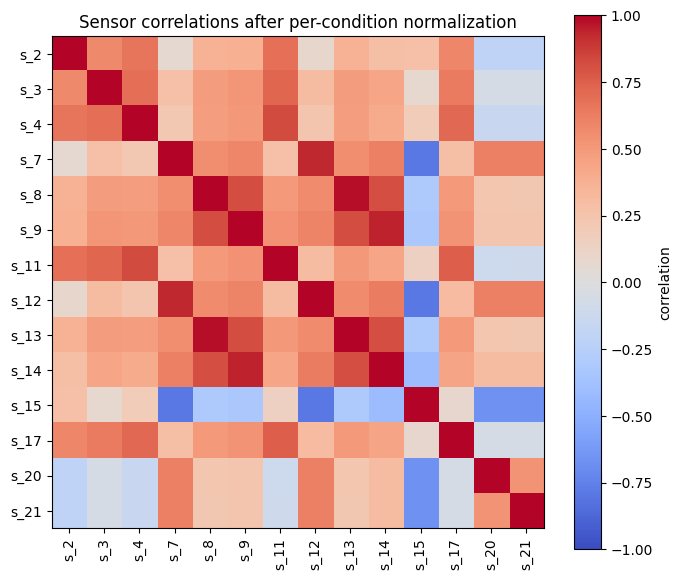

Strongest correlated pairs:
s_8  s_13    0.978199
s_9  s_14    0.943601
s_7  s_12    0.929761
s_4  s_11    0.827769
s_9  s_13    0.817651
s_8  s_9     0.816639
dtype: float64


In [7]:
corr = train_norm[keep_sensors].corr()

fig, ax = plt.subplots(figsize=(7,6))
im = ax.imshow(corr, cmap='coolwarm', vmin=-1, vmax=1)
ax.set_xticks(range(len(keep_sensors))); ax.set_xticklabels(keep_sensors, rotation=90)
ax.set_yticks(range(len(keep_sensors))); ax.set_yticklabels(keep_sensors)
plt.colorbar(im, label='correlation')
plt.title('Sensor correlations after per-condition normalization')
plt.tight_layout()
plt.savefig('/mnt/user-data/outputs/sensor_correlation_heatmap.png', dpi=120)
plt.show()

# flag the strongest pairs
pairs = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack()
print('Strongest correlated pairs:')
print(pairs.abs().sort_values(ascending=False).head(6))

## 6. Build RUL labels (train only)

Same definition as notebook 1: `RUL = max_cycle_for_engine - current_cycle`, clipped at 125. Test engines are truncated before failure by design, so RUL for test comes from a separate ground-truth file in the official C-MAPSS release, not from this formula — we're not using test RUL until the evaluation stage.

In [8]:
def add_rul(df, clip_at=125):
    max_cycle = df.groupby('unit_number')['time_cycles'].transform('max')
    df = df.copy()
    df['RUL'] = (max_cycle - df['time_cycles']).clip(upper=clip_at)
    return df

train_norm = add_rul(train_norm, clip_at=125)
train_norm[['unit_number','time_cycles','RUL']].head()

,unit_number,time_cycles,RUL
0,1,1,125
1,1,2,125
2,1,3,125
3,1,4,125
4,1,5,125


## 7. Save the processed data

This is what every downstream notebook (baseline, Alternative 1, Alternative 2) will load — same 14 sensors, same normalization, same RUL definition, so the three-way comparison stays fair.

In [9]:
import os
os.makedirs('/home/claude/project/data', exist_ok=True)

final_cols = ['unit_number', 'time_cycles', 'op_cond'] + keep_sensors
train_out = train_norm[final_cols + ['RUL']]
test_out  = test_norm[final_cols]

train_out.to_csv('/home/claude/project/data/train_FD004_processed.csv', index=False)
test_out.to_csv('/home/claude/project/data/test_FD004_processed.csv', index=False)

print('Saved. Final feature set:', keep_sensors)
print('Train processed shape:', train_out.shape)
print('Test processed shape: ', test_out.shape)

Saved. Final feature set: ['s_2', 's_3', 's_4', 's_7', 's_8', 's_9', 's_11', 's_12', 's_13', 's_14', 's_15', 's_17', 's_20', 's_21']
Train processed shape: (61249, 18)
Test processed shape:  (41214, 17)
